
# Budget Variance Analysis

**Domain:** Finance / FP&A Analytics  |  **Role:** Data Analyst  |  **Tools:** Python, pandas, matplotlib, seaborn

**Problem statement:** A company plans a budget for every department at the start of the year. Every month the finance team needs to know where actual spending went above or below the budget, which departments and cost categories cause the biggest gaps, and what the year end spend will look like if the current trend continues. This notebook builds that variance report.

**What this notebook does**
1. Creates a monthly budget vs actual dataset (department and cost category level)
2. Calculates variance (amount and %) and marks it Favorable or Unfavorable
3. Flags the line items that are more than 10% off budget
4. Shows department, category and monthly trend charts
5. Forecasts the year end spend using the run rate
6. Saves an Excel variance report

In [1]:
!pip install -q pandas matplotlib seaborn openpyxl

## Step 1: Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
np.random.seed(7)
print("libraries ready")

libraries ready


## Step 2: Create the budget vs actual data
This is a sample company dataset (budget plan and actual spend) for 6 departments, 4 cost categories and 12 months. Budget is the plan, actual is what was really spent.

In [3]:
departments = ["Sales", "Marketing", "Operations", "IT", "HR", "Finance"]
categories = ["Salaries", "Software and Tools", "Travel", "Vendor Services"]
months = pd.date_range("2025-01-01", periods=12, freq="MS")

base_budget = {
    "Sales": [120000, 15000, 20000, 18000],
    "Marketing": [80000, 25000, 10000, 45000],
    "Operations": [150000, 12000, 8000, 60000],
    "IT": [110000, 40000, 3000, 30000],
    "HR": [60000, 8000, 4000, 15000],
    "Finance": [70000, 10000, 3000, 12000]
}

# some departments overspend or underspend on purpose so the analysis has something to find
overspend_bias = {
    "Sales": 1.04, "Marketing": 1.12, "Operations": 1.02, "IT": 1.09, "HR": 0.96, "Finance": 0.98
}

rows = []
for dept in departments:
    for c_index in range(len(categories)):
        cat = categories[c_index]
        monthly_budget = base_budget[dept][c_index]
        for m_index in range(12):
            budget = monthly_budget * (1 + 0.01 * m_index)
            noise = np.random.normal(1, 0.06)
            actual = budget * overspend_bias[dept] * noise
            if cat == "Travel" and m_index in [5, 6, 10]:
                actual = actual * 1.35
            if dept == "Marketing" and cat == "Vendor Services" and m_index >= 8:
                actual = actual * 1.25
            rows.append([months[m_index], dept, cat, round(budget, 2), round(actual, 2)])

df = pd.DataFrame(rows, columns=["Month", "Department", "Category", "Budget", "Actual"])
print("Shape:", df.shape)
df.head(10)

Shape: (288, 5)


,Month,Department,Category,Budget,Actual
0,2025-01-01,Sales,Salaries,120000.0,137458.66
1,2025-02-01,Sales,Salaries,121200.0,122524.17
2,2025-03-01,Sales,Salaries,122400.0,127546.67
3,2025-04-01,Sales,Salaries,123600.0,131687.03
4,2025-05-01,Sales,Salaries,124800.0,123648.25
5,2025-06-01,Sales,Salaries,126000.0,131056.24
6,2025-07-01,Sales,Salaries,127200.0,132280.93
7,2025-08-01,Sales,Salaries,128400.0,119476.87
8,2025-09-01,Sales,Salaries,129600.0,143013.84
9,2025-10-01,Sales,Salaries,130800.0,140933.22


## Step 3: Calculate variance
Variance = Actual - Budget. For expenses, spending more than budget is **Unfavorable**, spending less is **Favorable**.

In [4]:
df["Variance"] = df["Actual"] - df["Budget"]
df["Variance_%"] = df["Variance"] / df["Budget"] * 100
df["Status"] = np.where(df["Variance"] > 0, "Unfavorable", "Favorable")
df["Flag"] = np.where(df["Variance_%"].abs() > 10, "Check", "OK")
df["MonthName"] = df["Month"].dt.strftime("%b")

total_budget = df["Budget"].sum()
total_actual = df["Actual"].sum()
total_variance = total_actual - total_budget

print("Total Budget :", round(total_budget, 0))
print("Total Actual :", round(total_actual, 0))
print("Total Variance:", round(total_variance, 0), "(", round(total_variance / total_budget * 100, 2), "% )")
print("Line items flagged (more than 10% off budget):", (df["Flag"] == "Check").sum(), "out of", len(df))

Total Budget : 11748480.0
Total Actual : 12347825.0
Total Variance: 599345.0 ( 5.1 % )
Line items flagged (more than 10% off budget): 95 out of 288


## Step 4: Variance by department

   Department     Budget      Actual   Variance  Variance_%
0   Marketing  2025600.0  2350126.92  324526.92       16.02
1          IT  2316780.0  2513011.16  196231.16        8.47
2       Sales  2190180.0  2292212.14  102032.14        4.66
3  Operations  2911800.0  2972618.96   60818.96        2.09
4     Finance  1202700.0  1167828.33  -34871.67       -2.90
5          HR  1101420.0  1052027.47  -49392.53       -4.48


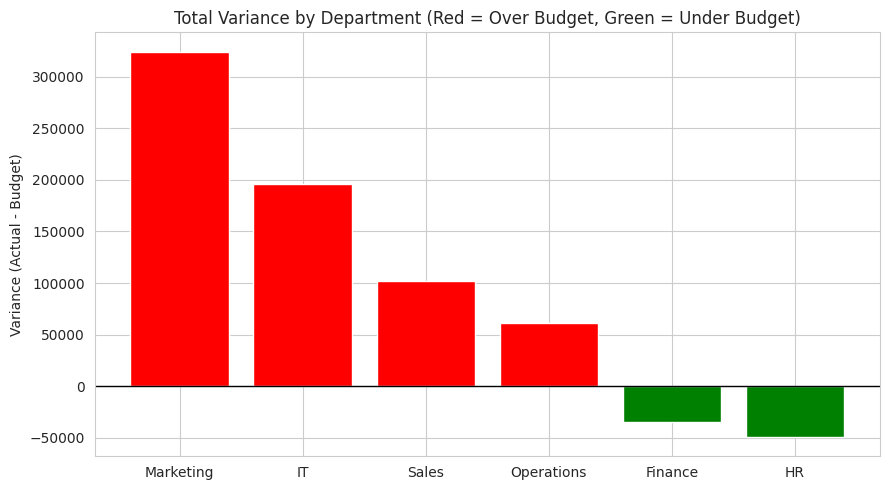

In [5]:
dept_summary = df.groupby("Department").agg(Budget=("Budget", "sum"), Actual=("Actual", "sum")).reset_index()
dept_summary["Variance"] = dept_summary["Actual"] - dept_summary["Budget"]
dept_summary["Variance_%"] = dept_summary["Variance"] / dept_summary["Budget"] * 100
dept_summary = dept_summary.sort_values("Variance", ascending=False).reset_index(drop=True)
print(dept_summary.round(2))

plt.figure(figsize=(9, 5))
colors = ["red" if v > 0 else "green" for v in dept_summary["Variance"]]
plt.bar(dept_summary["Department"], dept_summary["Variance"], color=colors)
plt.axhline(0, color="black", linewidth=1)
plt.title("Total Variance by Department (Red = Over Budget, Green = Under Budget)")
plt.ylabel("Variance (Actual - Budget)")
plt.tight_layout()
plt.savefig("variance_by_department.png", dpi=150)
plt.show()

## Step 5: Variance by cost category

             Category     Budget      Actual   Variance  Variance_%
2              Travel   607680.0   684940.95   77260.95       12.71
1  Software and Tools  1392600.0  1483931.13   91331.13        6.56
3     Vendor Services  2278800.0  2425882.38  147082.38        6.45
0            Salaries  7469400.0  7753070.52  283670.52        3.80


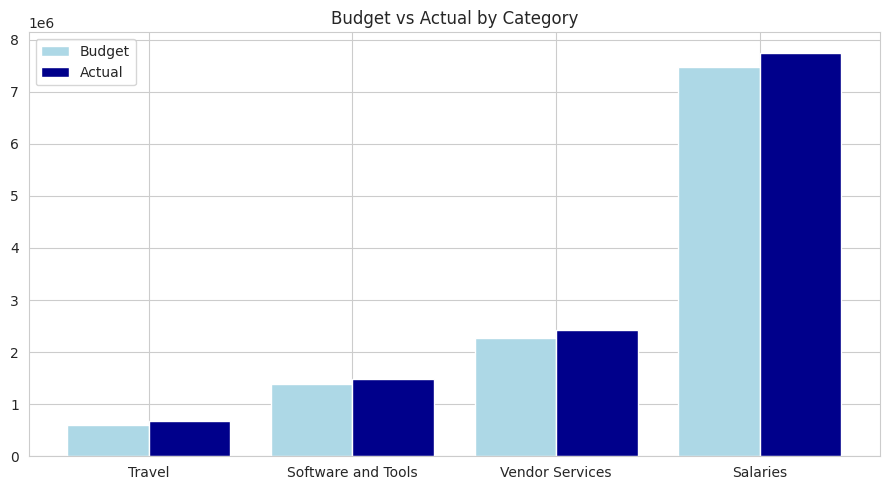

In [6]:
cat_summary = df.groupby("Category").agg(Budget=("Budget", "sum"), Actual=("Actual", "sum")).reset_index()
cat_summary["Variance"] = cat_summary["Actual"] - cat_summary["Budget"]
cat_summary["Variance_%"] = cat_summary["Variance"] / cat_summary["Budget"] * 100
cat_summary = cat_summary.sort_values("Variance_%", ascending=False)
print(cat_summary.round(2))

x = np.arange(len(cat_summary))
plt.figure(figsize=(9, 5))
plt.bar(x - 0.2, cat_summary["Budget"], width=0.4, label="Budget", color="lightblue")
plt.bar(x + 0.2, cat_summary["Actual"], width=0.4, label="Actual", color="darkblue")
plt.xticks(x, cat_summary["Category"])
plt.title("Budget vs Actual by Category")
plt.legend()
plt.tight_layout()
plt.savefig("budget_vs_actual_by_category.png", dpi=150)
plt.show()

## Step 6: Department x Month heatmap
Shows exactly which department had a problem in which month.

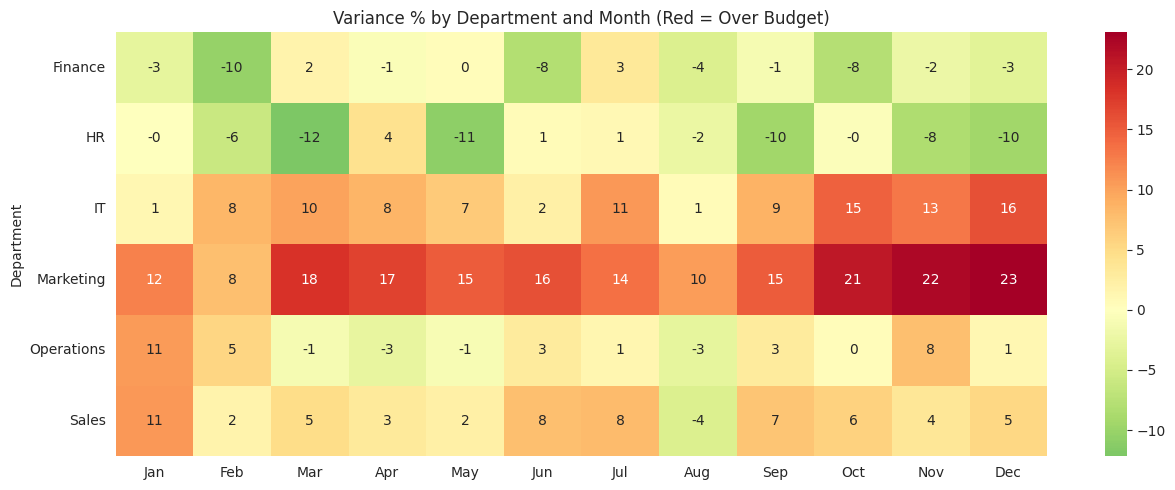

In [7]:
heat = df.groupby(["Department", "Month"]).agg(Budget=("Budget", "sum"), Actual=("Actual", "sum")).reset_index()
heat["Variance_%"] = (heat["Actual"] - heat["Budget"]) / heat["Budget"] * 100
heat["MonthName"] = heat["Month"].dt.strftime("%b")
heat_table = heat.pivot(index="Department", columns="Month", values="Variance_%")
heat_table.columns = [m.strftime("%b") for m in heat_table.columns]

plt.figure(figsize=(13, 5))
sns.heatmap(heat_table, annot=True, fmt=".0f", cmap="RdYlGn_r", center=0)
plt.title("Variance % by Department and Month (Red = Over Budget)")
plt.tight_layout()
plt.savefig("variance_heatmap.png", dpi=150)
plt.show()

## Step 7: Monthly trend and year to date (YTD)

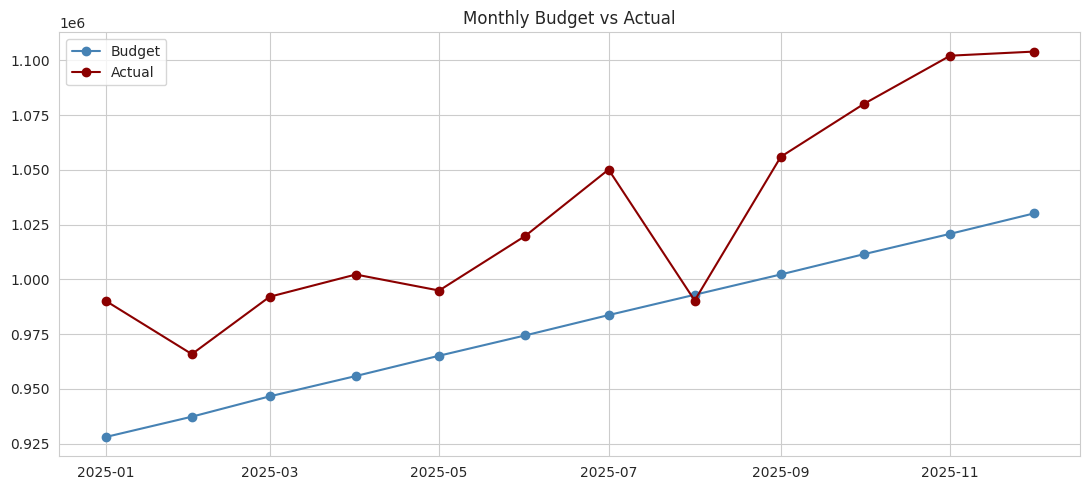

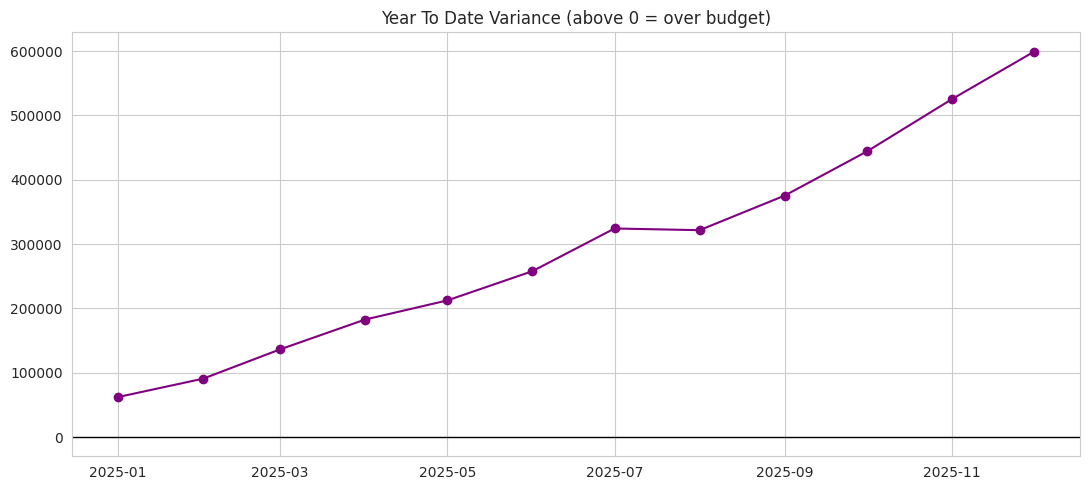

,Month,Budget,Actual,Variance,YTD_Variance
0,2025-01-01,928000.0,990175.0,62175.0,62175.0
1,2025-02-01,937280.0,965854.0,28574.0,90749.0
2,2025-03-01,946560.0,992051.0,45491.0,136240.0
3,2025-04-01,955840.0,1002210.0,46370.0,182610.0
4,2025-05-01,965120.0,994900.0,29780.0,212390.0
5,2025-06-01,974400.0,1019817.0,45417.0,257807.0
6,2025-07-01,983680.0,1050142.0,66462.0,324270.0
7,2025-08-01,992960.0,990328.0,-2632.0,321637.0
8,2025-09-01,1002240.0,1055986.0,53746.0,375384.0
9,2025-10-01,1011520.0,1080195.0,68675.0,444059.0


In [8]:
monthly = df.groupby("Month").agg(Budget=("Budget", "sum"), Actual=("Actual", "sum")).reset_index()
monthly["Variance"] = monthly["Actual"] - monthly["Budget"]
monthly["YTD_Budget"] = monthly["Budget"].cumsum()
monthly["YTD_Actual"] = monthly["Actual"].cumsum()
monthly["YTD_Variance"] = monthly["YTD_Actual"] - monthly["YTD_Budget"]

plt.figure(figsize=(11, 5))
plt.plot(monthly["Month"], monthly["Budget"], marker="o", label="Budget", color="steelblue")
plt.plot(monthly["Month"], monthly["Actual"], marker="o", label="Actual", color="darkred")
plt.title("Monthly Budget vs Actual")
plt.legend()
plt.tight_layout()
plt.savefig("monthly_trend.png", dpi=150)
plt.show()

plt.figure(figsize=(11, 5))
plt.plot(monthly["Month"], monthly["YTD_Variance"], marker="o", color="purple")
plt.axhline(0, color="black", linewidth=1)
plt.title("Year To Date Variance (above 0 = over budget)")
plt.tight_layout()
plt.savefig("ytd_variance.png", dpi=150)
plt.show()

monthly[["Month", "Budget", "Actual", "Variance", "YTD_Variance"]].round(0)

## Step 8: Top problem line items
The 10 biggest overspends and the 5 biggest savings (department + category level for the full year).

In [9]:
lines = df.groupby(["Department", "Category"]).agg(Budget=("Budget", "sum"), Actual=("Actual", "sum")).reset_index()
lines["Variance"] = lines["Actual"] - lines["Budget"]
lines["Variance_%"] = lines["Variance"] / lines["Budget"] * 100

top_over = lines.sort_values("Variance", ascending=False).head(10)
top_under = lines.sort_values("Variance").head(5)

print("TOP 10 OVERSPENDS")
print(top_over.round(1).to_string(index=False))
print()
print("TOP 5 SAVINGS")
print(top_under.round(1).to_string(index=False))

TOP 10 OVERSPENDS
Department           Category    Budget    Actual  Variance  Variance_%
 Marketing           Salaries 1012800.0 1145359.8  132559.8        13.1
 Marketing    Vendor Services  569700.0  701457.0  131757.0        23.1
        IT           Salaries 1392600.0 1496028.8  103428.8         7.4
     Sales           Salaries 1519200.0 1578856.5   59656.5         3.9
Operations           Salaries 1899000.0 1958236.8   59236.8         3.1
        IT Software and Tools  506400.0  559545.6   53145.6        10.5
        IT    Vendor Services  379800.0  412822.8   33022.8         8.7
 Marketing Software and Tools  316500.0  346678.3   30178.3         9.5
 Marketing             Travel  126600.0  156631.8   30031.8        23.7
     Sales             Travel  253200.0  275845.3   22645.3         8.9

TOP 5 SAVINGS
Department        Category   Budget   Actual  Variance  Variance_%
        HR        Salaries 759600.0 716579.9  -43020.1        -5.7
   Finance        Salaries 886200.0 85800

## Step 9: Year end forecast
Simple method: take the average actual spend of the last 3 months and assume the same for the months that are left. To make this realistic, the first 9 months are treated as 'closed' and the last 3 months are forecast.

In [10]:
closed = monthly.iloc[:9]
remaining_months = 3

last3_avg = closed["Actual"].tail(3).mean()
forecast_remaining = last3_avg * remaining_months
forecast_year_end = closed["Actual"].sum() + forecast_remaining
full_year_budget = monthly["Budget"].sum()

print("Actual spend (first 9 months):", round(closed["Actual"].sum(), 0))
print("Average of last 3 closed months:", round(last3_avg, 0))
print("Forecast year end spend:", round(forecast_year_end, 0))
print("Full year budget:", round(full_year_budget, 0))
print("Forecast overrun:", round(forecast_year_end - full_year_budget, 0), "(", round((forecast_year_end - full_year_budget) / full_year_budget * 100, 2), "% )")

# department wise forecast
dept_closed = df[df["Month"] <= months[8]].groupby("Department")["Actual"].sum()
dept_last3 = df[(df["Month"] > months[5]) & (df["Month"] <= months[8])].groupby("Department")["Actual"].sum() / 3
dept_forecast = dept_closed + dept_last3 * remaining_months
dept_budget = df.groupby("Department")["Budget"].sum()
forecast_table = pd.DataFrame({"Full Year Budget": dept_budget, "Forecast": dept_forecast})
forecast_table["Forecast Overrun"] = forecast_table["Forecast"] - forecast_table["Full Year Budget"]
forecast_table["Overrun_%"] = forecast_table["Forecast Overrun"] / forecast_table["Full Year Budget"] * 100
forecast_table = forecast_table.sort_values("Overrun_%", ascending=False)
print()
print(forecast_table.round(1))

Actual spend (first 9 months): 9061464.0
Average of last 3 closed months: 1032152.0
Forecast year end spend: 12157920.0
Full year budget: 11748480.0
Forecast overrun: 409440.0 ( 3.49 % )

            Full Year Budget   Forecast  Forecast Overrun  Overrun_%
Department                                                          
Marketing          2025600.0  2286743.9          261143.9       12.9
IT                 2316780.0  2448244.1          131464.1        5.7
Sales              2190180.0  2268639.8           78459.8        3.6
Operations         2911800.0  2931500.6           19700.6        0.7
Finance            1202700.0  1171406.1          -31293.9       -2.6
HR                 1101420.0  1051385.4          -50034.6       -4.5


## Step 10: Key insights (calculated from the output above)

In [11]:
worst_dept = dept_summary.iloc[0]
best_dept = dept_summary.iloc[-1]
worst_cat = cat_summary.iloc[0]
worst_line = top_over.iloc[0]
flag_count = (df["Flag"] == "Check").sum()

print("KEY INSIGHTS")
print("-" * 50)
print("1. Total actual spend is", round(total_variance / total_budget * 100, 2), "% above the total budget (gap =", round(total_variance, 0), ")")
print("2. Biggest overspending department:", worst_dept["Department"], "(", round(worst_dept["Variance_%"], 1), "% over budget )")
print("3. Most under budget department:", best_dept["Department"], "(", round(best_dept["Variance_%"], 1), "% )")
print("4. Category with highest overrun:", worst_cat["Category"], "(", round(worst_cat["Variance_%"], 1), "% )")
print("5. Single biggest problem line:", worst_line["Department"], "-", worst_line["Category"], "(", round(worst_line["Variance"], 0), "over )")
print("6.", flag_count, "of", len(df), "monthly line items are more than 10% away from budget")
print("7. If the trend continues the year will end", round(forecast_year_end - full_year_budget, 0), "over budget")
print()
print("RECOMMENDATIONS")
print("- Review the departments at the top of the overrun list in the next budget meeting")
print("- Add a travel approval rule because travel spikes in some months")
print("- Re-forecast every month using the run rate instead of waiting for year end")

KEY INSIGHTS
--------------------------------------------------
1. Total actual spend is 5.1 % above the total budget (gap = 599345.0 )
2. Biggest overspending department: Marketing ( 16.0 % over budget )
3. Most under budget department: HR ( -4.5 % )
4. Category with highest overrun: Travel ( 12.7 % )
5. Single biggest problem line: Marketing - Salaries ( 132560.0 over )
6. 95 of 288 monthly line items are more than 10% away from budget
7. If the trend continues the year will end 409440.0 over budget

RECOMMENDATIONS
- Review the departments at the top of the overrun list in the next budget meeting
- Add a travel approval rule because travel spikes in some months
- Re-forecast every month using the run rate instead of waiting for year end


## Step 11: Save the Excel variance report

In [12]:
with pd.ExcelWriter("budget_variance_report.xlsx") as writer:
    df.drop(columns=["MonthName"]).to_excel(writer, sheet_name="Detailed Data", index=False)
    dept_summary.to_excel(writer, sheet_name="By Department", index=False)
    cat_summary.to_excel(writer, sheet_name="By Category", index=False)
    monthly.to_excel(writer, sheet_name="Monthly Trend", index=False)
    top_over.to_excel(writer, sheet_name="Top Overspends", index=False)
    forecast_table.to_excel(writer, sheet_name="Year End Forecast")

print("Saved files:", [f for f in os.listdir(".") if f.endswith(".png") or f.endswith(".xlsx")])

Saved files: ['variance_by_department.png', 'budget_variance_report.xlsx', 'variance_heatmap.png', 'ytd_variance.png', 'budget_vs_actual_by_category.png', 'monthly_trend.png']


In [ ]:

# ============================================================
# UNIVERSAL COLAB PROJECT AUTO-SAVE
# Structure: Parent Folder / Notebook Name / All Project Files
# ============================================================

import os
import json
import shutil
from pathlib import Path
from google.colab import auth, _message
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload
from google.auth import default

# 1. DESTINATION GOOGLE DRIVE FOLDER
PARENT_FOLDER_ID = "1RJ_KbIui8TyupB2kr3c-N93lt2OE0nAk"

# 2. AUTHENTICATE
auth.authenticate_user()
credentials, _ = default()
drive = build("drive", "v3", credentials=credentials)

# 3. DETECT CURRENT NOTEBOOK
notebook_data = _message.blocking_request("get_ipynb")

if "ipynb" in notebook_data:
    notebook_data = notebook_data["ipynb"]

project_name = (
    notebook_data.get("metadata", {})
    .get("colab", {})
    .get("name", "")
)

if not project_name:
    project_name = input("Enter your Colab notebook name (e.g. RAG): ").strip()

project_name = Path(project_name).stem

if not project_name:
    raise ValueError("Project name is missing.")

print("Project detected:", project_name)

# 4. FIND OR CREATE PROJECT FOLDER
query = (
    f"'{PARENT_FOLDER_ID}' in parents "
    f"and name = '{project_name}' "
    "and mimeType = 'application/vnd.google-apps.folder' "
    "and trashed = false"
)

results = drive.files().list(
    q=query,
    fields="files(id,name)",
    supportsAllDrives=True,
    includeItemsFromAllDrives=True
).execute()

if results.get("files"):
    PROJECT_FOLDER_ID = results["files"][0]["id"]
else:
    folder = drive.files().create(
        body={
            "name": project_name,
            "mimeType": "application/vnd.google-apps.folder",
            "parents": [PARENT_FOLDER_ID]
        },
        fields="id"
    ).execute()

    PROJECT_FOLDER_ID = folder["id"]

# 5. UPLOAD FILES WITHOUT ZIP
SKIP_DIRS = {
    "drive", "sample_data", ".config",
    ".cache", "__pycache__"
}

uploaded = 0
failed = []

def find_existing_file(name, parent_id):
    q = (
        f"'{parent_id}' in parents "
        f"and name = '{name}' "
        "and trashed = false"
    )
    found = drive.files().list(
        q=q,
        fields="files(id)",
        supportsAllDrives=True,
        includeItemsFromAllDrives=True
    ).execute()
    return found.get("files", [])

def upload_file(local_path, parent_id):
    global uploaded

    filename = os.path.basename(local_path)

    metadata = {
        "name": filename,
        "parents": [parent_id]
    }

    media = MediaFileUpload(
        local_path,
        resumable=True
    )

    existing = find_existing_file(filename, parent_id)

    if existing:
        drive.files().update(
            fileId=existing[0]["id"],
            media_body=media,
            supportsAllDrives=True
        ).execute()
    else:
        drive.files().create(
            body=metadata,
            media_body=media,
            fields="id",
            supportsAllDrives=True
        ).execute()

    uploaded += 1
    print("Saved:", filename)

def upload_directory(local_dir, drive_parent_id):
    for item in os.scandir(local_dir):

        if item.is_dir(follow_symlinks=False):

            if item.name in SKIP_DIRS:
                continue

            existing = find_existing_file(
                item.name, drive_parent_id
            )

            if existing:
                subfolder_id = existing[0]["id"]
            else:
                result = drive.files().create(
                    body={
                        "name": item.name,
                        "mimeType": "application/vnd.google-apps.folder",
                        "parents": [drive_parent_id]
                    },
                    fields="id",
                    supportsAllDrives=True
                ).execute()
                subfolder_id = result["id"]

            upload_directory(item.path, subfolder_id)

        elif item.is_file(follow_symlinks=False):
            try:
                upload_file(item.path, drive_parent_id)
            except Exception as error:
                failed.append((item.name, str(error)))
                print("Upload failed:", item.name, error)

# 6. SAVE EXECUTED NOTEBOOK
notebook_path = f"/content/{project_name}.ipynb"

with open(notebook_path, "w", encoding="utf-8") as f:
    json.dump(notebook_data, f, ensure_ascii=False, indent=2)

# 7. UPLOAD PROJECT FILES
upload_directory("/content", PROJECT_FOLDER_ID)

# 8. FINAL REPORT
print("\n======================================")
print("PROJECT BACKUP COMPLETED")
print("======================================")
print("Project:", project_name)
print("Uploaded files:", uploaded)
print("Failed files:", len(failed))
print(
    "Folder:",
    f"https://drive.google.com/drive/folders/{PROJECT_FOLDER_ID}"
)

if failed:
    print("\nFailed uploads:")
    for name, error in failed:
        print(name, error)


---
*Built by Akshat Kesharwani | Portfolio: https://akshatkesharwani-info.github.io/ | GitHub: https://github.com/akshatkesharwani-info*